In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(suppress = True, precision = 5)



### Liczenie gradientu funkcji

In [3]:
def function(x):
    func = 5 * x[0]**2 + 10 * x[1]**2
    return func

x = np.array([2.0,4.0])

In [4]:
def gradient(f,x,h = 1e-5):
    grad = np.zeros_like(x, dtype = float)
    for i in range(len(x)):
        xp = x.copy()
        xl = x.copy()
        xp[i] += h
        xl[i] -= h
        grad[i] = (f(xp) - f(xl)) / (2 * h)
    return grad
print(gradient(function, x))

[20. 80.]


### Gradient descent

In [5]:
def gradient_descent(f,xs ,lr = 0.01, iteration = 500, tol = 1e-5):
    x = np.asarray(xs , dtype = float).copy()
    history = [x.copy()]
    for i in range(iteration):
        grad = gradient(f, x)
        if np.linalg.norm(grad) < tol:
            break
        else:
            x = x - lr * grad
            history.append(x.copy())

    return x , np.array(history)
gradient_descent(function, np.array([5,8]))


(array([0., 0.]),
 array([[5.     , 8.     ],
        [4.5    , 6.4    ],
        [4.05   , 5.12   ],
        [3.645  , 4.096  ],
        [3.2805 , 3.2768 ],
        [2.95245, 2.62144],
        [2.6572 , 2.09715],
        [2.39148, 1.67772],
        [2.15234, 1.34218],
        [1.9371 , 1.07374],
        [1.74339, 0.85899],
        [1.56905, 0.68719],
        [1.41215, 0.54976],
        [1.27093, 0.4398 ],
        [1.14384, 0.35184],
        [1.02946, 0.28147],
        [0.92651, 0.22518],
        [0.83386, 0.18014],
        [0.75047, 0.14412],
        [0.67543, 0.11529],
        [0.60788, 0.09223],
        [0.54709, 0.07379],
        [0.49239, 0.05903],
        [0.44315, 0.04722],
        [0.39883, 0.03778],
        [0.35895, 0.03022],
        [0.32305, 0.02418],
        [0.29075, 0.01934],
        [0.26167, 0.01547],
        [0.23551, 0.01238],
        [0.21196, 0.0099 ],
        [0.19076, 0.00792],
        [0.17168, 0.00634],
        [0.15452, 0.00507],
        [0.13906, 0.00406],
  

### Rysowanie wykresu

In [6]:
def plot_3d(f,history, title = 'Optymalizacja'):
    history = np.array(history)
    pad = 1.0
    x_min , x_max  = history[:, 0].min() - pad, history[:, 0].max() + pad
    y_min , y_max = history[:, 1].min() - pad, history[:, 1].max() + pad

    X , Y = np.meshgrid(
        np.linspace(x_min , x_max, 100), np.linspace(y_min, y_max, 100)
    )

    Z = np.vectorize(lambda x, y: f([x, y]))(X, Y)
    Z_hist = np.array([f(pt) for pt in history])

    fig  = plt.figure(figsize = (10,7))
    ax = fig.add_subplot(111, projection = '3d')

    ax.plot_surface(X, Y , Z, cmap ='viridis', alpha = 0.55, edgecolor = 'none')
    ax.plot(
        history[:, 0],
        history[:, 1],
        Z_hist, 
        color = 'red',
        marker = 'o',
        markersize= 3,
        linewidth = 2,
    )

    ax.scatter(
        history[0,0],
        history[0,1],
        Z_hist[0],
        color = 'green',
        s = 80,
        label = 'Start',
    )

    ax.scatter(
        history[-1, 0],
        history[-1, 1],
        Z_hist[-1],
        color = 'blue',
        marker = '*',  
        s = 150,
        label = 'Minimum'
    )

    ax.set_title(title)
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('f(X,Y)')
    ax.legend()
    plt.show()

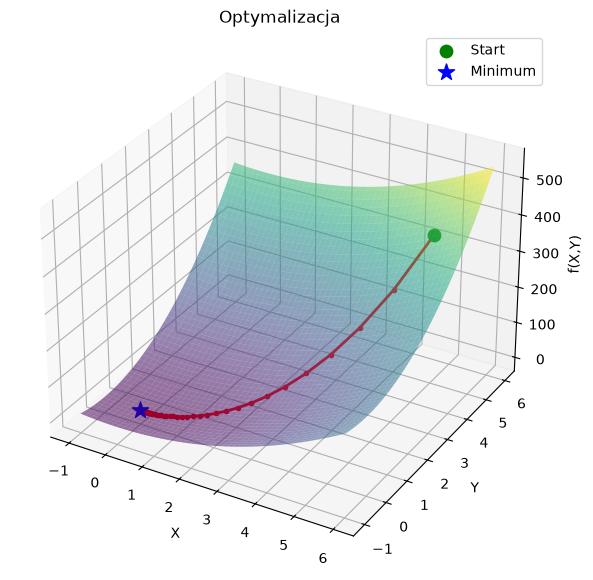

In [7]:
X_min, history = gradient_descent(function, np.array([5,5]))

plot_3d(function, history)

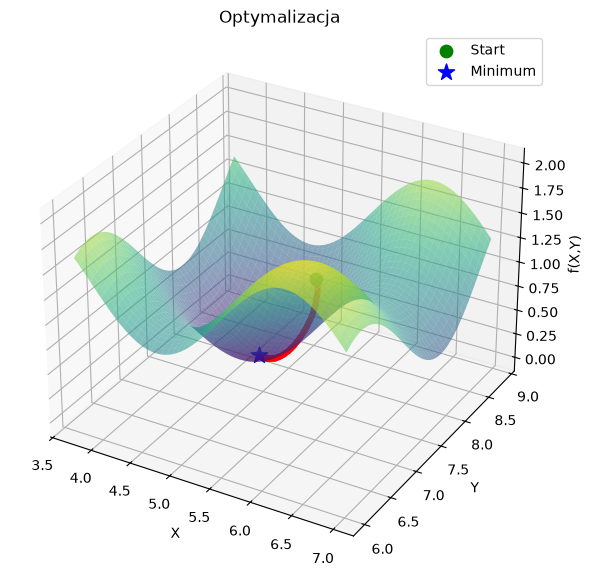

[4.71253 7.85393]


In [18]:
def f(x):
    return 1 - np.sin(x[0]) ** 2 + np.cos(x[1]) ** 2

xmin , hist = gradient_descent(f, np.array([6,7]))

plot_3d(f, hist)
print(xmin)